# 03 — Figures

Charts built only from the prepared tables in `data/processed/` (created by `02_analysis_prep.ipynb`).
Shared style, pitch setup and coordinate conversion live in `src/plots.py`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from src import data as d
from src import plots as P

P.apply_style()

---
## H1 — England turnovers and the two Sweden goals

**Coordinates.** StatsBomb stores each team's events from its own attacking direction. England events are
plotted as stored (England attack left → right). Every Sweden event is mirrored into England's frame with
`x' = 120 - x`, `y' = 80 - y` (`P.to_attacking_frame`). The goal-sequence tables already carry
`x_eng_frame` / `y_eng_frame`; they are cross-checked against the manual conversion below.

**Inputs.** `h1_england_turnovers_first_half`, `h1_goal_sequence_02min`, `h1_goal_sequence_25min`.
The turnover table links each turnover to a Sweden `shot_id` but does not store the shot's coordinates,
so the two non-goal shot locations are taken from `h5_sweden_shots` (joined on `shot_id`, Sweden frame,
then converted).

In [2]:
turnovers = d.load_processed("h1_england_turnovers_first_half")
seq02 = d.load_processed("h1_goal_sequence_02min")
seq25 = d.load_processed("h1_goal_sequence_25min")
swe_shots = d.load_processed("h5_sweden_shots")

n_turnovers = len(turnovers)
n_pressure = int(turnovers.under_pressure.sum())
linked = turnovers[turnovers.led_to_sweden_shot]
linked_xg = linked.shot_xg.sum()
n_first_half_shots = int((swe_shots.period == 1).sum())
print(f"turnovers: {n_turnovers}, under pressure: {n_pressure}, shot-linked: {len(linked)} "
      f"({linked_xg:.2f} xG), goals: {int(turnovers.led_to_goal.sum())}, "
      f"Sweden first-half shots: {n_first_half_shots}")
assert n_turnovers == 36 and n_pressure == 6
assert len(linked) == n_first_half_shots == linked.shot_id.nunique() == 4

turnovers: 36, under pressure: 6, shot-linked: 4 (0.77 xG), goals: 2, Sweden first-half shots: 4


In [3]:
def fmt_minute(display_minute: int, period: int = 1) -> str:
    """Broadcast-style minute with first-half stoppage time, e.g. 46 -> 45+1'."""
    m = int(display_minute)
    return f"45+{m - 45}'" if period == 1 and m > 45 else f"{m}'"


def surname(name: str) -> str:
    return name.split()[-1]


# --- Sweden shot locations in England's frame -------------------------------------------
shot_loc = swe_shots.set_index("id")[["shot_x", "shot_y"]]
linked = linked.join(shot_loc, on="shot_id")
linked["shot_x_eng"], linked["shot_y_eng"] = P.to_attacking_frame(linked.shot_x, linked.shot_y)

# --- 2' goal: Asllani's press on Carter, Walsh's loss, Asllani's shot -------------------
press02 = seq02[(seq02.type == "Pressure") & seq02.player_name.str.contains("Asllani")].iloc[0]
loss02 = seq02[(seq02.type == "Pass") & seq02.player_name.str.contains("Walsh") & seq02.outcome.eq("Incomplete")].iloc[0]
block02 = seq02[(seq02.type == "Block") & seq02.player_name.str.contains("Angeldal")].iloc[0]
shot02 = seq02[seq02.type == "Shot"].iloc[0]

# --- 25' goal: Angeldal's tackle on Hemp, Blackstenius's shot ---------------------------
tackle25 = seq25[(seq25.type == "Duel") & seq25.player_name.str.contains("Angeldal")].iloc[0]
lost25 = seq25[(seq25.type == "Dispossessed") & seq25.player_name.str.contains("Hemp")].iloc[0]
shot25 = seq25[seq25.type == "Shot"].iloc[0]

# Cross-check: manual conversion of Sweden events == x_eng_frame / y_eng_frame in the tables.
for ev in [press02, block02, shot02, tackle25, shot25]:
    xe, ye = P.to_attacking_frame(ev.location[0], ev.location[1])
    assert np.isclose(xe, ev.x_eng_frame) and np.isclose(ye, ev.y_eng_frame), ev.type
# The goal shots in the sequences must be the shots linked in the turnover table.
for shot in [shot02, shot25]:
    row = linked[linked.shot_id == shot.id]
    assert len(row) == 1 and np.isclose(row.shot_x_eng.iloc[0], shot.x_eng_frame)

print(f"2'  press  ({press02.timestamp}) at ({press02.x_eng_frame:.1f}, {press02.y_eng_frame:.1f}); "
      f"Walsh loss ({loss02.timestamp}) at ({loss02.x_eng_frame:.1f}, {loss02.y_eng_frame:.1f}); "
      f"Angeldal block ({block02.timestamp}) at ({block02.x_eng_frame:.1f}, {block02.y_eng_frame:.1f})")
print(f"25' tackle ({tackle25.timestamp}) at ({tackle25.x_eng_frame:.1f}, {tackle25.y_eng_frame:.1f}); "
      f"Hemp dispossessed at ({lost25.x_eng_frame:.1f}, {lost25.y_eng_frame:.1f})")
linked[["display_minute", "player_name", "loss_type", "under_pressure", "loss_x", "loss_y",
        "shot_player", "shot_x", "shot_y", "shot_x_eng", "shot_y_eng", "shot_xg", "led_to_goal"]]

2'  press  (00:01:37.773) at (24.8, 36.4); Walsh loss (00:01:39.979) at (32.0, 29.9); Angeldal block (00:01:40.114) at (35.1, 29.8)
25' tackle (00:24:29.903) at (81.3, 13.0); Hemp dispossessed at (81.4, 13.1)


,display_minute,player_name,loss_type,under_pressure,loss_x,loss_y,shot_player,shot_x,shot_y,shot_x_eng,shot_y_eng,shot_xg,led_to_goal
2,2,Keira Walsh,Pass incomplete,False,32.0,29.9,Kosovare Asllani,107.6,48.0,12.4,32.0,0.262062,True
4,5,Hannah Hampton,Miscontrol,False,18.5,37.7,Emma Stina Blackstenius,114.8,30.1,5.2,49.9,0.135633,False
17,25,Lauren Hemp,Pass out of play,False,64.2,13.3,Emma Stina Blackstenius,113.5,49.8,6.5,30.2,0.286011,True
35,46,Ella Toone,Pass incomplete,True,111.3,24.3,Fridolina Rolfö,104.0,42.6,16.0,37.4,0.082706,False


legend: 5 entries on one line, font 9.5 pt, right edge at 0.948 of figure width


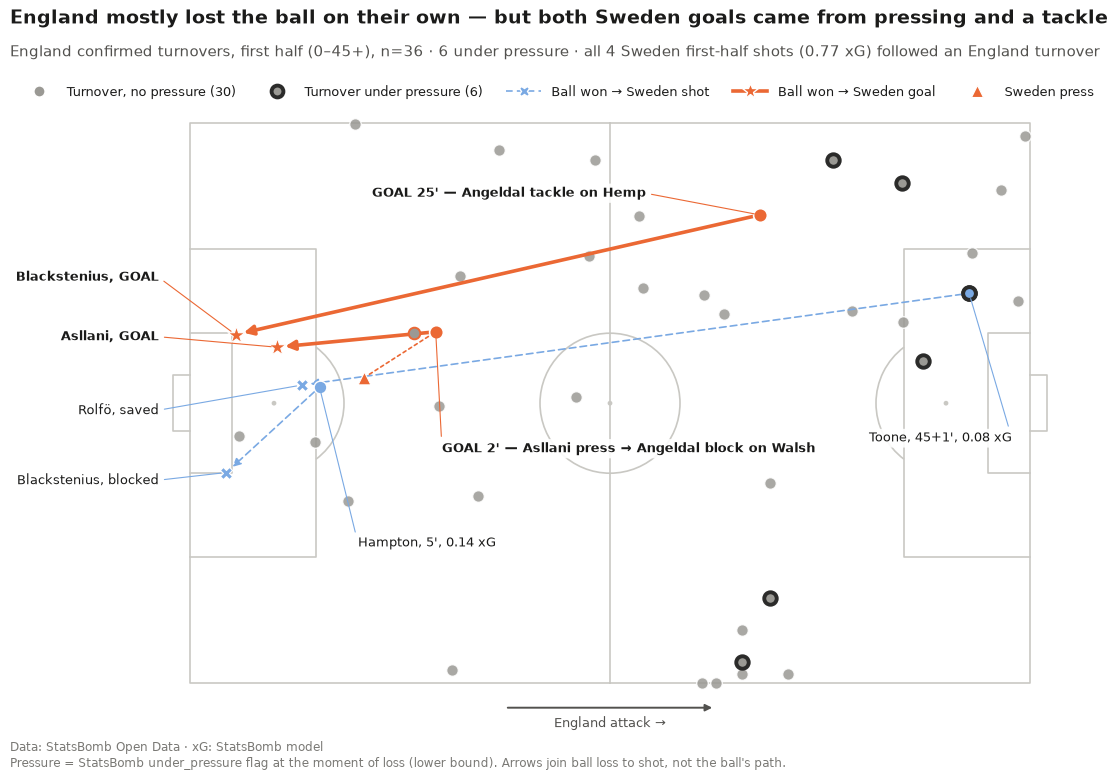

In [4]:
C = P.COLORS
# Pitch shifted right to leave a margin for the shot labels left of England's goal.
pitch, fig, ax = P.make_pitch(figsize=(12, 8), axes_rect=(0.10, 0.07, 0.88, 0.77))

DOT = 70
# Walsh's incomplete pass (2' goal chain) is drawn as its own layer: still a grey turnover dot,
# with a thin orange ring and drawn above the goal arrow.
is_walsh02 = turnovers.id.eq(loss02.id)
assert is_walsh02.sum() == 1 and not turnovers.loc[is_walsh02, "under_pressure"].iloc[0]
walsh02 = turnovers[is_walsh02]
plain = turnovers[~turnovers.under_pressure & ~is_walsh02]
pressed = turnovers[turnovers.under_pressure]

# Layer 1: all confirmed turnovers (grey); pressured ones get a thick dark ring.
sc_plain = pitch.scatter(plain.loss_x, plain.loss_y, ax=ax, s=DOT, color=C["neutral"],
                         edgecolors=C["background"], linewidths=1.0, alpha=0.85, zorder=3)
sc_pressed = pitch.scatter(pressed.loss_x, pressed.loss_y, ax=ax, s=DOT * 1.15, color=C["neutral"],
                           edgecolors=C["neutral_edge"], linewidths=P.PRESSURE_RING_WIDTH, zorder=3)


def arrow(start, end, color, lw=1.8, ls="-"):
    ax.annotate("", xy=end, xytext=start, zorder=4,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls, shrinkA=5, shrinkB=6,
                                mutation_scale=12 if ls != "-" else 14))


def ring(row):
    return C["neutral_edge"] if row.under_pressure else C["background"]


def ring_width(row):
    return P.PRESSURE_RING_WIDTH if row.under_pressure else 1.0


# Layer 2 (secondary): non-goal turnovers that led to a Sweden shot - thinner, lighter, dashed.
S2 = C["accent_secondary"]
non_goal = linked[~linked.led_to_goal]
shot_markers = []
for r in non_goal.itertuples():
    pitch.scatter(r.loss_x, r.loss_y, ax=ax, s=DOT * 1.2, color=S2,
                  edgecolors=ring(r), linewidths=ring_width(r), zorder=5)
    arrow((r.loss_x, r.loss_y), (r.shot_x_eng, r.shot_y_eng), S2, lw=1.2, ls=(0, (4, 2.5)))
    shot_markers.append(pitch.scatter(r.shot_x_eng, r.shot_y_eng, ax=ax, s=DOT * 1.1, marker="X",
                                      color=S2, edgecolors=C["background"],
                                      linewidths=0.8, zorder=5))

# Layer 3 (primary): the two goal sequences (strongest colour, bold).
G = C["goal"]
# 2': press marker, dashed line to Angeldal's block on Walsh's pass, arrow block -> shot.
# (Walsh's loss itself stays a grey turnover dot; the ball was won at the block.)
pitch.scatter(press02.x_eng_frame, press02.y_eng_frame, ax=ax, s=DOT * 1.2, marker="^",
              color=G, edgecolors=C["background"], linewidths=0.8, zorder=5)
ax.annotate("", xy=(block02.x_eng_frame, block02.y_eng_frame), xytext=(press02.x_eng_frame, press02.y_eng_frame),
            zorder=4, arrowprops=dict(arrowstyle="-", color=G, lw=1.2, ls=(0, (2, 2)), shrinkA=5, shrinkB=5))
pitch.scatter(block02.x_eng_frame, block02.y_eng_frame, ax=ax, s=DOT * 1.4, color=G,
              edgecolors=C["background"], linewidths=1.2, zorder=5)
arrow((block02.x_eng_frame, block02.y_eng_frame), (shot02.x_eng_frame, shot02.y_eng_frame), G, lw=2.6)
sc_walsh = pitch.scatter(walsh02.loss_x, walsh02.loss_y, ax=ax, s=DOT, color=C["neutral"],
                         edgecolors=G, linewidths=1.4, zorder=4.5)  # above the arrow (zorder 4)
# 25': Angeldal's tackle on Hemp, arrow -> shot.
pitch.scatter(lost25.x_eng_frame, lost25.y_eng_frame, ax=ax, s=DOT * 1.4, color=G,
              edgecolors=C["background"], linewidths=1.2, zorder=5)
arrow((lost25.x_eng_frame, lost25.y_eng_frame), (shot25.x_eng_frame, shot25.y_eng_frame), G, lw=2.6)
goal_markers = [
    pitch.scatter(s.x_eng_frame, s.y_eng_frame, ax=ax, s=DOT * 2.4, marker="*", color=G,
                  edgecolors=C["background"], linewidths=0.8, zorder=6)
    for s in [shot02, shot25]
]

# Turnover / sequence labels with leader lines, placed in empty areas of the pitch.
LABEL_POS = {"Hampton": (24, 60), "Toone": (97, 45)}
for r in non_goal.itertuples():
    text = f"{surname(r.player_name)}, {fmt_minute(r.display_minute)}, {r.shot_xg:.2f} xG"
    P.label(ax, text, (r.loss_x, r.loss_y), LABEL_POS[surname(r.player_name)], color=S2)
P.label(ax, f"GOAL {fmt_minute(shot02.t // 60 + 1)} — Asllani press → Angeldal block on Walsh",
        (block02.x_eng_frame, block02.y_eng_frame), (36, 46.5), color=G, weight="bold")
P.label(ax, f"GOAL {fmt_minute(shot25.t // 60 + 1)} — Angeldal tackle on Hemp",
        (lost25.x_eng_frame, lost25.y_eng_frame), (26, 10), color=G, weight="bold")

# Shot labels: right-aligned in the margin left of England's goal, ordered top to bottom
# like the shots themselves, so leader lines never cross.
SHOT_OUTCOME_TEXT = {"Goal": "GOAL", "Saved": "saved", "Blocked": "blocked", "Saved to Post": "saved"}
shot_labels = pd.concat([
    non_goal.assign(goal=False)[["shot_player", "shot_outcome", "shot_x_eng", "shot_y_eng", "goal"]],
    pd.DataFrame([dict(shot_player=s.player_name, shot_outcome="Goal", shot_x_eng=s.x_eng_frame,
                       shot_y_eng=s.y_eng_frame, goal=True) for s in [shot02, shot25]]),
]).sort_values("shot_y_eng").reset_index(drop=True)
SHOT_LABEL_X = -4.5
SHOT_LABEL_Y = [22, 30.5, 41, 51]  # one slot per shot, top to bottom
assert len(shot_labels) == len(SHOT_LABEL_Y)
for r, y in zip(shot_labels.itertuples(), SHOT_LABEL_Y):
    P.label(ax, f"{surname(r.shot_player)}, {SHOT_OUTCOME_TEXT[r.shot_outcome]}",
            (r.shot_x_eng, r.shot_y_eng), (SHOT_LABEL_X, y), ha="right",
            color=G if r.goal else S2, weight="bold" if r.goal else "normal")

P.add_attack_arrow(ax, "England attack →")

# Title, legend, footer.
P.add_title(
    fig,
    "England mostly lost the ball on their own — but both Sweden goals came from pressing and a tackle",
    f"England confirmed turnovers, first half (0–45+), n={n_turnovers} · {n_pressure} under pressure · "
    f"all {n_first_half_shots} Sweden first-half shots ({linked_xg:.2f} xG) followed an England turnover",
)
handles = [
    Line2D([], [], ls="", marker="o", ms=8, mfc=C["neutral"], mec=C["background"],
           label=f"Turnover, no pressure ({n_turnovers - n_pressure})"),
    Line2D([], [], ls="", marker="o", ms=8.5, mfc=C["neutral"], mec=C["neutral_edge"],
           mew=P.PRESSURE_RING_WIDTH, label=f"Turnover under pressure ({n_pressure})"),
    Line2D([], [], ls=(0, (4, 2.5)), lw=1.2, color=S2, marker="X", ms=7.5, mec=C["background"],
           label="Ball won → Sweden shot"),
    Line2D([], [], ls="-", lw=2.6, color=G, marker="*", ms=12, mec=C["background"],
           label="Ball won → Sweden goal"),
    Line2D([], [], ls="", marker="^", ms=8.5, mfc=G, mec=C["background"], mew=0.8,
           label="Sweden press"),
]
# One line above the pitch: shrink the legend font (never wrap) until it fits inside the right margin.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for legend_fs in np.arange(P.FONT_SIZES["legend"], 6.9, -0.5):
    leg = fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.04, 0.885), ncol=len(handles),
                     frameon=False, fontsize=legend_fs, handlelength=2.6, columnspacing=1.8)
    right = leg.get_window_extent(renderer).transformed(fig.transFigure.inverted()).x1
    if right <= 0.96:
        break
    leg.remove()
print(f"legend: {len(handles)} entries on one line, font {legend_fs:.1f} pt, right edge at {right:.3f} of figure width")
assert right <= 0.96
P.add_footer(fig, note="Pressure = StatsBomb under_pressure flag at the moment of loss (lower bound). "
                       "Arrows join ball loss to shot, not the ball's path.")

In [5]:
# Check the plotted positions: count markers and confirm Sweden shots sit at the LEFT goal (England's goal).
n_grey = len(sc_plain.get_offsets()) + len(sc_pressed.get_offsets()) + len(sc_walsh.get_offsets())
assert len(sc_walsh.get_offsets()) == 1  # Walsh's 2' loss: one of the 36, drawn with an orange ring
n_ring = len(sc_pressed.get_offsets())
plotted_shots = np.vstack([m.get_offsets() for m in shot_markers + goal_markers])
print(f"grey dots plotted: {n_grey}; under-pressure markers: {n_ring}")
print("Sweden shots as plotted (England frame):")
for (x, y) in plotted_shots:
    print(f"  x'={x:.1f}, y'={y:.1f}")
assert n_grey == 36 and n_ring == 6
assert (plotted_shots[:, 0] < 30).all(), "Sweden shots are not near England's (left) goal"
print("OK: all Sweden shots are within 30 yd of the left goal line (England's goal).")

path = P.save_figure(fig, "01_h1_turnovers")
print("saved:", d.relative_path(path))
plt.show()

grey dots plotted: 36; under-pressure markers: 6
Sweden shots as plotted (England frame):
  x'=5.2, y'=49.9
  x'=16.0, y'=37.4
  x'=12.4, y'=32.0
  x'=6.5, y'=30.2
OK: all Sweden shots are within 30 yd of the left goal line (England's goal).


saved: figures/01_h1_turnovers.png
